# TP2 - Etapa 2: entrenamiento, evaluación y comparación de modelos

Notebook de entrenamiento y estudio de resultados: evaluación de la búsqueda por similitud
(Etapa 1, NDCG@10), fine-tuning de ResNet (Modelo A), CNN propia (Modelo B) y comparación entre
modelos (ver `ENUNCIADO.md`, secciones 4.3 y 5). **Ambos modelos son obligatorios.**

Requisitos previos (en el fork):
- Funciones de la Etapa 1 implementadas en `src/lib/services/similarity_service.py`.
- `train_classifier`, `evaluate_classifier` y `extract_custom_embedding` implementadas en
  `src/lib/services/classifier_service.py` (esta notebook solo las orquesta).
- Splits y conjunto independiente generados en `1-pre-processing.ipynb`.

**Notebook en Google Colab:** no se usa. La notebook se entrega ejecutada en el repositorio
(opción 1 de la sección 8.2 del enunciado); se corrió en local con GPU (GTX 1650, 4 GB).

## Equipo
- Alumno 1 : Facundo Quinteros — Q-0493/6 — @FacuQuinteros03
- Alumno 2 : Roberto Lasarte — L-3370/7 — @RoberLasarte332

## 1. Clonar el repositorio

Solo si se trabaja en Colab (en local la notebook se corre desde la raíz del repositorio).

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/FacuQuinteros03/tuia-dog-recognition-app.git"
    !git clone -b feature/tp2-razas-perros $REPO_URL proyecto
    %cd proyecto
print("Colab:", IN_COLAB)

Colab: False


## 2. Instalar dependencias

En local se usa el entorno de `requirements.txt`. En Colab solo se instala lo que falta.

In [2]:
if IN_COLAB:
    !pip install -q pydantic-settings python-dotenv kagglehub albumentations onnxruntime

## 3. Configuración del entorno

Se desactiva pgvector y se usa la base vectorial JSON: para evaluar no hace falta la base de datos
(sección 5). La configuración se define por variables de entorno **antes** de importar `lib`.
Los pesos preentrenados se cachean en `models/torch` (`TORCH_HOME`, igual que en la app) y los
embeddings calculados en `output/nb2/`, que está fuera del control de versiones.

In [3]:
import os
import random
import time
import warnings
from pathlib import Path

ROOT = Path.cwd()
os.environ["USE_PGVECTOR"] = "false"
os.environ.setdefault("TORCH_HOME", str(ROOT / "models" / "torch"))
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from lib.config import settings
from lib.preprocessing import bgr_to_rgb, read_bgr

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATASET = ROOT / "data" / "dataset"
CACHE = ROOT / "output" / "nb2"
CACHE.mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 90
# Figuras en JPEG: las grillas de fotos en PNG hacen que la notebook pese demasiado para GitHub.
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("jpeg", pil_kwargs={"quality": 85})
print("dataset_path:", settings.dataset_path)
print("GPU disponible:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

/root/venvs/tp2/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


dataset_path: data/dataset/clean
GPU disponible: True NVIDIA GeForce GTX 1650


## 4. Dataset y splits

Se usan los splits de `1-pre-processing.ipynb` (`data/splits.csv`, con las imágenes ya copiadas a
`data/dataset/clean/<split>/<raza>/`) y el conjunto independiente (`data/independent_sources.csv`,
imágenes en `data/dataset/independent/<raza>/` y `data/dataset/independent_scenes/<escena>/`).
Si el dataset no está, se descarga y hay que ejecutar primero la notebook 1.

In [4]:
if not settings.dataset_path.is_dir():
    !python scripts/download_dataset.py
    raise SystemExit("Ejecutar 1-pre-processing.ipynb para generar data/dataset/clean y data/splits.csv")

splits = pd.read_csv(ROOT / "data" / "splits.csv")
splits["abs_path"] = [str(settings.dataset_path / p) for p in splits.path]
SETS = {s: splits[splits.split == s].reset_index(drop=True) for s in ("train", "valid", "test")}

indep_all = pd.read_csv(ROOT / "data" / "independent_sources.csv")
indep_all["abs_path"] = [
    str((DATASET / "independent" if g == "breed" else DATASET / "independent_scenes") / l / Path(f).name)
    for g, l, f in zip(indep_all.group, indep_all.label, indep_all.file)
]
SETS["independent"] = indep_all
assert all(Path(p).is_file() for df in SETS.values() for p in df.abs_path), "faltan imágenes"

summary = pd.DataFrame({
    "imágenes": {k: len(v) for k, v in SETS.items()},
    "razas": {k: (v.breed if "breed" in v else v.label[v.group == "breed"]).nunique() for k, v in SETS.items()},
})
display(summary)
print(indep_all.group.value_counts().to_string())

,imágenes,razas
train,5994,70
valid,1285,70
test,1285,70
independent,133,24


group
breed        100
no_dog        20
multi_dog     13


## 5. Etapa 1 — Evaluación de la búsqueda por similitud (baseline)

**Protocolo** (enunciado 4.3):

- **Galería:** las imágenes de `train` (5994). **Consultas:** `test` y las 100 imágenes de razas
  del conjunto independiente, que nunca se indexan. `valid` se usa solo para calibrar el umbral.
- **Extractor:** `SimilarityService.extract_embedding`, la misma función que usa la app: ResNet18
  preentrenado en ImageNet sin la capa `fc` (embedding de 512 = `EMBEDDING_DIM`), con el
  preprocesamiento compartido de `lib/preprocessing.py` y normalización L2.
- **Por qué ResNet18:** su embedding coincide con `EMBEDDING_DIM=512` y con el del ResNet18
  fine-tuned del Modelo A, así la misma tabla de pgvector sirve para los dos y la comparación
  baseline vs. fine-tuned (sección 9) es sobre la misma arquitectura.
- **Búsqueda:** como sugiere el enunciado, la galería se guarda en una matriz de `numpy` y se busca
  con un producto matricial. En 5.2 se verifica que da los mismos vecinos que
  `search_similar_images` del servicio.
- **Raza predicha:** `predict_breed_from_neighbors` del servicio (voto ponderado por similitud).
- **Métricas:** NDCG@10 con relevancia binaria e `n_relevant` = imágenes de la raza en la galería
  (`ndcg_at_k` de `src/lib/evaluation/metrics.py`), precision@10 y accuracy de la raza predicha.

### 5.1 Embeddings de la galería y de las consultas

Se calculan una vez y se guardan en `output/nb2/` (si el archivo existe y tiene la misma cantidad
de filas, se reutiliza).

In [5]:
from lib.bootstrap import build_similarity, build_store
from lib.evaluation.metrics import ndcg_at_k
from lib.schemas import Neighbor

similarity = build_similarity(settings, build_store(settings))


def embed_set(name, paths, extractor, tag="baseline"):
    f = CACHE / f"emb_{tag}_{name}.npy"
    if f.exists():
        E = np.load(f)
        if len(E) == len(paths):
            return E
    t0 = time.time()
    E = np.asarray([extractor(read_bgr(p)) for p in paths], dtype=np.float32)
    print(f"{tag}/{name}: {len(E)} embeddings en {time.time() - t0:.0f} s")
    np.save(f, E)
    return E


EMB = {k: embed_set(k, v.abs_path.tolist(), similarity.extract_embedding) for k, v in SETS.items()}

# Tiempo de extracción por imagen (incluye lectura y preprocesamiento)
sample = SETS["test"].abs_path.tolist()[:50]
t0 = time.time()
for p in sample:
    similarity.extract_embedding(read_bgr(p))
ms = (time.time() - t0) / len(sample) * 1000
print({k: v.shape for k, v in EMB.items()})
norms = np.linalg.norm(EMB["train"], axis=1)
print(f"normas L2 de la galería: min {norms.min():.4f}, max {norms.max():.4f}")
print(f"extract_embedding: {ms:.1f} ms por imagen en {DEVICE}")

2026-11-25 02:38:47.144151515 [W:onnxruntime:Default, device_discovery.cc:325 DiscoverDevicesForPlatform] GPU device discovery failed: device_discovery.cc:92 ReadFileContents Failed to open file: "/sys/class/drm/card0/device/vendor"
INFO:lib.bootstrap:Using JSON file vector store


INFO:lib.services.similarity_service:Backbone baseline ResNet18 (ImageNet) cargado en cuda


{'train': (5994, 512), 'valid': (1285, 512), 'test': (1285, 512), 'independent': (133, 512)}
normas L2 de la galería: min 1.0000, max 1.0000
extract_embedding: 164.2 ms por imagen en cuda


In [6]:
GALLERY = EMB["train"]
G_BREED = SETS["train"].breed.to_numpy()
G_PATH = SETS["train"].path.to_numpy()
N_IN_GALLERY = pd.Series(G_BREED).value_counts()

is_breed = (SETS["independent"].group == "breed").to_numpy()
QUERIES = {
    "test": (EMB["test"], SETS["test"].breed.to_numpy(), SETS["test"].abs_path.to_numpy()),
    "independiente": (EMB["independent"][is_breed], SETS["independent"].label[is_breed].to_numpy(),
                      SETS["independent"].abs_path[is_breed].to_numpy()),
    "valid": (EMB["valid"], SETS["valid"].breed.to_numpy(), SETS["valid"].abs_path.to_numpy()),
}


def score_matrix(Q, metric):
    """Similitud consulta x galería con las mismas fórmulas que SimilarityService.similarity."""
    dot = Q @ GALLERY.T
    if metric == "cosine":
        return dot / (np.linalg.norm(Q, axis=1)[:, None] * np.linalg.norm(GALLERY, axis=1)[None, :])
    sq = (Q ** 2).sum(1)[:, None] + (GALLERY ** 2).sum(1)[None, :] - 2 * dot
    return 1.0 / (1.0 + np.sqrt(np.maximum(sq, 0.0)))


def evaluate(name, metric="cosine", k=10, threshold=0.0):
    """Una fila por consulta: NDCG@10, precision@10, raza predicha (con k vecinos) y score top-1."""
    Q, q_breed, q_path = QUERIES[name]
    S = score_matrix(Q, metric)
    order = np.argsort(-S, axis=1)[:, : max(k, 10)]
    similarity.similarity_metric, similarity.similarity_threshold = metric, threshold
    rows = []
    for i in range(len(Q)):
        top = order[i]
        rel = (G_BREED[top[:10]] == q_breed[i]).astype(float)
        neigh = [Neighbor(path=G_PATH[j], breed=G_BREED[j], score=float(S[i, j])) for j in top[:k]]
        pred, conf = similarity.predict_breed_from_neighbors(neigh)
        rows.append({
            "path": q_path[i], "breed": q_breed[i], "pred": pred, "ok": pred == q_breed[i],
            "ndcg@10": ndcg_at_k(rel, k=10, n_relevant=int(N_IN_GALLERY.get(q_breed[i], 0))),
            "precision@10": rel.mean(), "top1_score": float(S[i, top[0]]), "conf": conf,
            "top10": top[:10],
        })
    similarity.similarity_metric, similarity.similarity_threshold = settings.similarity_metric, settings.similarity_threshold
    return pd.DataFrame(rows)

### 5.2 Verificación contra el servicio

La búsqueda vectorizada de la notebook tiene que devolver los mismos vecinos que
`search_similar_images`. Se arma una base JSON temporal con la galería (`EmbeddingStore.save`, en
una sola escritura) y se comparan los Top-10 de 20 consultas de `test`, con las dos métricas.

In [7]:
import tempfile
from lib.schemas import EmbeddingRecord
from lib.services.similarity_service import SimilarityService
from lib.storage.embedding_store import EmbeddingStore

tmp_store = EmbeddingStore(Path(tempfile.mkdtemp()) / "gallery.json")
tmp_store.save([EmbeddingRecord(id_imagen=str(i), embedding=e.tolist(), path=p, breed=b)
                for i, (e, p, b) in enumerate(zip(GALLERY, G_PATH, G_BREED))])
check_rows = []
for metric in ("cosine", "l2"):
    svc = SimilarityService(tmp_store, metric, 0.0, 10, settings.image_size, "baseline")
    ev = evaluate("test", metric).head(20)
    gallery_records = tmp_store.all()
    svc.store = type("Cached", (), {"all": lambda self: gallery_records})()  # evita releer el JSON
    S_nb = score_matrix(QUERIES["test"][0][:20], metric)
    same_set = same_order = 0
    max_diff = 0.0
    for i in range(20):
        res = svc.search_similar_images(QUERIES["test"][0][i].tolist(), 10)
        nb_paths = list(G_PATH[ev.top10[i]])
        same_set += set(n.path for n in res) == set(nb_paths)
        same_order += [n.path for n in res] == nb_paths
        max_diff = max(max_diff, max(abs(n.score - S_nb[i, ev.top10[i][k]]) for k, n in enumerate(sorted(res, key=lambda n: nb_paths.index(n.path)))))
    check_rows.append({"métrica": metric, "consultas": 20, "mismo conjunto Top-10": same_set,
                       "mismo orden": same_order, "máx. diferencia de score": max_diff})
display(pd.DataFrame(check_rows))

,métrica,consultas,mismo conjunto Top-10,mismo orden,máx. diferencia de score
0,cosine,20,20,19,6.556511e-07
1,l2,20,20,19,6.556511e-07


### 5.3 Resultados: NDCG@10, precision@10 y accuracy

Sin umbral (`SIMILARITY_THRESHOLD = 0`), para medir la búsqueda en sí; el umbral se analiza en 5.7.

In [8]:
RESULTS = {(m, n): evaluate(n, m) for m in ("cosine", "l2") for n in ("test", "independiente", "valid")}
table = pd.DataFrame([
    {"métrica": m, "conjunto": n, "consultas": len(r), "NDCG@10": r["ndcg@10"].mean(),
     "NDCG@10 mediana": r["ndcg@10"].median(), "precision@10": r["precision@10"].mean(), "accuracy": r.ok.mean()}
    for (m, n), r in RESULTS.items() if n != "valid"
])
display(table.round(3))

,métrica,conjunto,consultas,NDCG@10,NDCG@10 mediana,precision@10,accuracy
0,cosine,test,1285,0.817,0.931,0.806,0.889
1,cosine,independiente,100,0.595,0.708,0.595,0.690
2,l2,test,1285,0.817,0.931,0.806,0.889
3,l2,independiente,100,0.595,0.708,0.595,0.690


**Interpretación.**

- **Sin entrenar nada, la búsqueda ya acierta la raza en el 89% de `test`** (70 clases; al azar
  sería 1,4%). El NDCG@10 medio es **0,817** y la mediana **0,931**: en la consulta típica casi
  todos los 10 vecinos son de la misma raza. Los pesos de ImageNet ya separan bien las razas,
  porque ImageNet incluye ~120 razas de perros entre sus 1000 clases.
- **En el conjunto independiente todo cae unos 20 puntos:** NDCG@10 **0,595** y accuracy **0,69**.
  No es que las razas sean otras (son 24 de las 70), sino el tipo de foto. Las imágenes de la
  galería son recortes centrados del perro (en la notebook 1, la caja de YOLO ocupa una mediana del
  88% de la imagen); las del conjunto independiente son fotos completas de Wikimedia Commons, con
  fondo, perros chicos dentro del cuadro y poses variadas. Los ejemplos de 5.8 lo muestran.
- **`cosine` y `l2` dan exactamente los mismos números** (ver 5.4).
- **Precisión de la estimación:** el conjunto independiente tiene 100 consultas, así que su
  accuracy tiene un margen de ±9 puntos (intervalo de 95%, binomial). En `test` (1285 consultas)
  el margen es de ±1,7 puntos. La diferencia de 20 puntos entre los dos es mucho mayor que ese
  margen.

### 5.4 `cosine` vs. `l2`

Las dos métricas dan exactamente el mismo resultado. Con embeddings normalizados
(‖a‖ = ‖b‖ = 1) la distancia euclídea es una función monótona del coseno,
‖a − b‖ = √(2 − 2·cos(a, b)), así que ordenan la galería igual. Solo cambia la escala del score:
`l2` devuelve 1 / (1 + ‖a − b‖), que para vectores unitarios va de 1/3 a 1, y el umbral tiene que
expresarse en la escala de la métrica configurada.

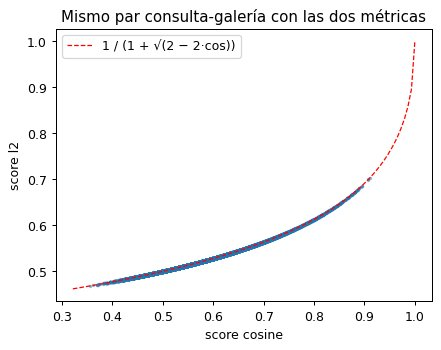

Consultas de test con el mismo Top-10 en las dos métricas: 100.0%


In [9]:
q = QUERIES["test"][0][:200]
c, l = score_matrix(q, "cosine").ravel(), score_matrix(q, "l2").ravel()
same_top = (np.argsort(-score_matrix(QUERIES["test"][0], "cosine"), 1)[:, :10]
            == np.argsort(-score_matrix(QUERIES["test"][0], "l2"), 1)[:, :10]).all(1).mean()
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(c[::50], l[::50], s=3, alpha=0.4)
xs = np.linspace(c.min(), 1, 100)
ax.plot(xs, 1 / (1 + np.sqrt(2 - 2 * xs)), "r--", lw=1, label="1 / (1 + √(2 − 2·cos))")
ax.set_xlabel("score cosine")
ax.set_ylabel("score l2")
ax.set_title("Mismo par consulta-galería con las dos métricas")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Consultas de test con el mismo Top-10 en las dos métricas: {same_top:.1%}")

### 5.5 Distribución del NDCG@10 y resultados por raza

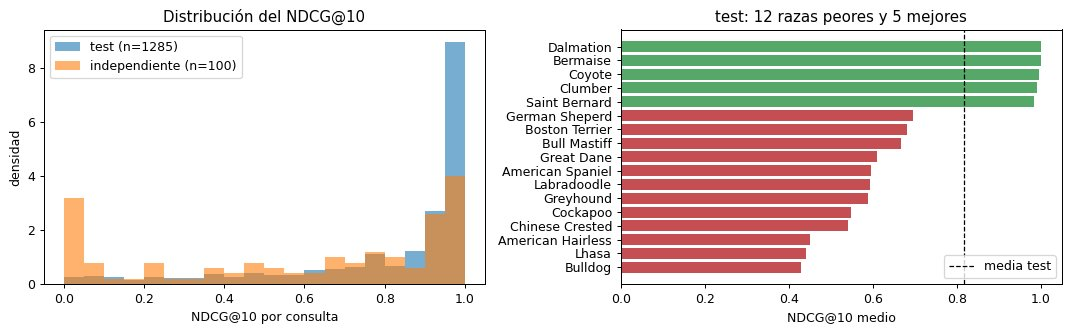

Fracción de consultas con NDCG@10 = 1: test 45.0% | independiente 20.0%
Fracción con NDCG@10 < 0.3: test 7.6% | independiente 27.0%


In [10]:
r_test, r_ind = RESULTS[("cosine", "test")], RESULTS[("cosine", "independiente")]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
bins = np.linspace(0, 1, 21)
axes[0].hist(r_test["ndcg@10"], bins=bins, alpha=0.6, density=True, label=f"test (n={len(r_test)})")
axes[0].hist(r_ind["ndcg@10"], bins=bins, alpha=0.6, density=True, label=f"independiente (n={len(r_ind)})")
axes[0].set_xlabel("NDCG@10 por consulta")
axes[0].set_ylabel("densidad")
axes[0].set_title("Distribución del NDCG@10")
axes[0].legend()

per_breed = r_test.groupby("breed").agg(ndcg=("ndcg@10", "mean"), acc=("ok", "mean"), n=("ok", "size")).sort_values("ndcg")
sel = pd.concat([per_breed.head(12), per_breed.tail(5)])
axes[1].barh(sel.index, sel.ndcg, color=["#c44e52"] * 12 + ["#55a868"] * 5)
axes[1].axvline(r_test["ndcg@10"].mean(), color="k", ls="--", lw=1, label="media test")
axes[1].set_xlabel("NDCG@10 medio")
axes[1].set_title("test: 12 razas peores y 5 mejores")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Fracción de consultas con NDCG@10 = 1:", f"test {(r_test['ndcg@10'] == 1).mean():.1%} |",
      f"independiente {(r_ind['ndcg@10'] == 1).mean():.1%}")
print("Fracción con NDCG@10 < 0.3:", f"test {(r_test['ndcg@10'] < 0.3).mean():.1%} |",
      f"independiente {(r_ind['ndcg@10'] < 0.3).mean():.1%}")

In [11]:
ind_breed = r_ind.groupby("breed").agg(n=("ok", "size"), ndcg=("ndcg@10", "mean"), acc=("ok", "mean"))
ind_breed = ind_breed.join(per_breed[["ndcg", "acc"]], rsuffix="_test").sort_values("ndcg")
ind_breed.columns = ["consultas", "NDCG@10 indep.", "accuracy indep.", "NDCG@10 test", "accuracy test"]
display(ind_breed.round(2))

,consultas,NDCG@10 indep.,accuracy indep.,NDCG@10 test,accuracy test
breed,,,,,
Poodle,3,0.17,0.33,0.76,0.83
Shih-Tzu,4,0.21,0.25,0.76,0.90
Shiba Inu,4,0.36,0.50,0.75,0.82
Chihuahua,5,0.38,0.40,0.92,1.00
French Bulldog,5,0.40,0.40,0.73,0.88
Dingo,2,0.41,0.50,0.79,0.90
Labrador,5,0.43,0.40,0.85,0.92
Border Collie,5,0.47,0.80,0.83,0.95
Bulldog,5,0.49,0.60,0.43,0.52


**Interpretación.**

- **Distribución:** en `test`, el 45% de las consultas tiene NDCG@10 = 1 (los 10 vecinos de la
  raza correcta) y solo el 7,6% queda por debajo de 0,3. En el conjunto independiente, el 20% es
  perfecto y el 27% queda por debajo de 0,3: la distribución es bimodal, o la búsqueda encuentra
  la raza o se va a otra.
- **Las razas peores de `test` son justamente los pares casi idénticos** que se vieron en la
  notebook 1 (sección 6.3): Bulldog (0,43), Lhasa (0,44), American Hairless (0,45), Chinese
  Crested, Cockapoo y Labradoodle. Las mejores son las de pelaje o color inconfundible
  (Dalmation y Bermaise con 1,0, Coyote, Clumber, Saint Bernard).
- **En el conjunto independiente el patrón es otro:** fallan Poodle (0,17), Shih-Tzu (0,21),
  Chihuahua (0,38) o Labrador (0,43), que en `test` andan bien (Chihuahua: 0,92). Esa caída viene
  del tipo de foto, no de confusión entre razas parecidas. Las que se sostienen (Dalmation,
  Golden Retriever, Doberman, Siberian Husky, Pug) tienen un color o un patrón de pelaje que
  se reconoce aunque cambie el encuadre. Con 2 a 5 imágenes por raza, estos valores por raza
  son orientativos.

### 5.6 Efecto de `TOP_K`

`TOP_K` es la cantidad de vecinos que votan la raza (el NDCG@10 siempre usa los 10 primeros).

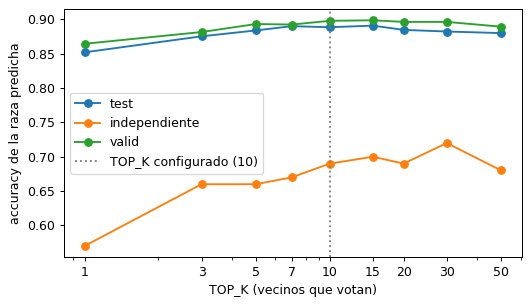

TOP_K,1,3,5,7,10,15,20,30,50
test,0.852,0.875,0.884,0.890,0.889,0.891,0.885,0.882,0.880
independiente,0.570,0.660,0.660,0.670,0.690,0.700,0.690,0.720,0.680
valid,0.865,0.882,0.893,0.893,0.898,0.899,0.896,0.896,0.889


In [12]:
KS = [1, 3, 5, 7, 10, 15, 20, 30, 50]
topk = pd.DataFrame({n: [evaluate(n, "cosine", k=k).ok.mean() for k in KS] for n in ("test", "independiente", "valid")}, index=KS)
topk.index.name = "TOP_K"
fig, ax = plt.subplots(figsize=(6, 3.5))
for n in topk:
    ax.plot(topk.index, topk[n], marker="o", label=n)
ax.axvline(settings.top_k, color="gray", ls=":", label=f"TOP_K configurado ({settings.top_k})")
ax.set_xscale("log")
ax.set_xticks(KS)
ax.set_xticklabels(KS)
ax.set_xlabel("TOP_K (vecinos que votan)")
ax.set_ylabel("accuracy de la raza predicha")
ax.legend()
plt.tight_layout()
plt.show()
display(topk.T.round(3))

**Interpretación.**

- **Con un solo vecino (`TOP_K = 1`) la accuracy es la más baja** (0,852 en `test`, 0,57 en el
  independiente): el vecino más cercano a veces es de una raza parecida y el voto lo corrige.
- **La accuracy sube hasta K ≈ 10–15 y después baja levemente en `test` y `valid`**
  (0,889 con 10, 0,880 con 50): con muchos vecinos entran imágenes de otras razas que votan.
- **Se mantiene `TOP_K = 10`:** está a menos de 0,2 puntos del máximo en `test` y en `valid`
  (la diferencia con K = 15 en `valid` es 1 consulta de 1285), coincide con el NDCG@10 y con las
  10 imágenes que muestra la interfaz. En el independiente la curva sube con K pero es ruidosa:
  cada imagen vale 1 punto.

### 5.7 Calibración de `SIMILARITY_THRESHOLD`

Si la similitud del vecino más cercano queda por debajo del umbral, el servicio devuelve
`unknown`. El objetivo es rechazar consultas que no se parecen a nada de la galería (por ejemplo,
una foto sin perro) sin rechazar perros de las razas conocidas.

**Criterio:** el umbral se calibra solo con `valid`, sin mirar test ni el conjunto independiente.
Se elige el percentil 0,1 del score top-1 de `valid` (redondeado hacia abajo a dos decimales): el
umbral más alto que rechaza como mucho 1 de cada 1000 perros de razas conocidas. Se prioriza no
rechazar perros porque, en la pestaña de la Etapa 1, un `unknown` sobre la foto de un perro es
peor que una raza dudosa sobre una foto sin perro (que además la Etapa 3 filtra con YOLO).
Después se mide, sin recalibrar, qué pasa con las fotos sin perro (`no_dog`), con las escenas de
varios perros (`multi_dog`) y con las fotos de razas del conjunto independiente.

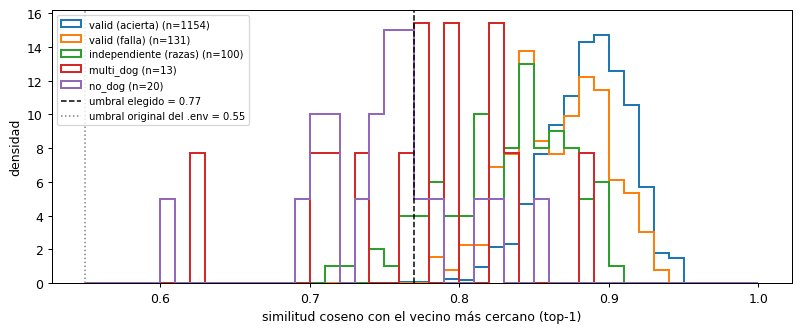

,valid rechazadas,accuracy valid (rechazo = error),indep. razas rechazadas,indep. rechazadas que estaban bien,accuracy indep. (rechazo = error),multi_dog rechazadas,no_dog rechazadas
umbral,,,,,,,
0.55,0.0%,89.8%,0.0%,0.0%,69.0%,0.0%,0.0%
0.70,0.0%,89.8%,0.0%,0.0%,69.0%,7.7%,10.0%
0.74,0.0%,89.8%,2.0%,0.0%,69.0%,30.8%,35.0%
0.76,0.0%,89.8%,5.0%,0.0%,69.0%,30.8%,60.0%
0.77,0.1%,89.7%,9.0%,0.0%,69.0%,38.5%,75.0%
0.78,0.2%,89.6%,13.0%,4.0%,65.0%,53.8%,80.0%
0.80,0.6%,89.4%,23.0%,8.0%,61.0%,69.2%,85.0%
0.82,2.1%,88.4%,37.0%,16.0%,53.0%,69.2%,90.0%
0.85,13.2%,80.2%,63.0%,36.0%,33.0%,92.3%,95.0%


SIMILARITY_THRESHOLD (cosine) = 0.77  |  equivalente en l2: 0.60


test con el umbral: 0.4% rechazadas, accuracy (rechazo = error) 0.887

Fotos sin perro que superan el umbral (Commons: categoría de origen):
                                            file                     category  top1
     no_dog/no_dog/Vulpes_vulpes_Mallnitz_04.jpg Sleeping cats; Vulpes vulpes 0.853
             no_dog/no_dog/Arabian_Red_Fox_1.jpg Sleeping cats; Vulpes vulpes 0.825
        no_dog/no_dog/Stanislaus_nach_der_OP.jpg Sleeping cats; Vulpes vulpes 0.819
no_dog/no_dog/Black_Cat_Sitia_Crete_Greece_2.jpg Sleeping cats; Vulpes vulpes 0.784
       no_dog/no_dog/Red_Fox_Vulpes_vulpes_4.jpg Sleeping cats; Vulpes vulpes 0.779


In [13]:
r_val = RESULTS[("cosine", "valid")]
S_scenes = {g: score_matrix(EMB["independent"][(SETS["independent"].group == g).to_numpy()], "cosine").max(1)
            for g in ("no_dog", "multi_dog")}
top1 = {
    "valid (acierta)": r_val.top1_score[r_val.ok].to_numpy(),
    "valid (falla)": r_val.top1_score[~r_val.ok].to_numpy(),
    "independiente (razas)": r_ind.top1_score.to_numpy(),
    "multi_dog": S_scenes["multi_dog"],
    "no_dog": S_scenes["no_dog"],
}
THRESHOLD = float(np.floor(np.percentile(r_val.top1_score, 0.1) * 100) / 100)

fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.linspace(0.55, 1.0, 46)
for name, v in top1.items():
    ax.hist(v, bins=bins, density=True, histtype="step", lw=1.6, label=f"{name} (n={len(v)})")
ax.axvline(THRESHOLD, color="k", ls="--", lw=1.2, label=f"umbral elegido = {THRESHOLD:.2f}")
ax.axvline(0.55, color="gray", ls=":", lw=1.2, label="umbral original del .env = 0.55")
ax.set_xlabel("similitud coseno con el vecino más cercano (top-1)")
ax.set_ylabel("densidad")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

rows = []
for thr in [0.55, 0.70, 0.74, 0.76, THRESHOLD, 0.78, 0.80, 0.82, 0.85]:
    keep_val, keep_ind = r_val.top1_score >= thr, r_ind.top1_score >= thr
    rows.append({
        "umbral": thr,
        "valid rechazadas": 1 - keep_val.mean(),
        "accuracy valid (rechazo = error)": (r_val.ok & keep_val).mean(),
        "indep. razas rechazadas": 1 - keep_ind.mean(),
        "indep. rechazadas que estaban bien": (r_ind.ok & ~keep_ind).mean(),
        "accuracy indep. (rechazo = error)": (r_ind.ok & keep_ind).mean(),
        "multi_dog rechazadas": (S_scenes["multi_dog"] < thr).mean(),
        "no_dog rechazadas": (S_scenes["no_dog"] < thr).mean(),
    })
thr_table = pd.DataFrame(rows).drop_duplicates("umbral").sort_values("umbral").set_index("umbral")
display(thr_table.style.format("{:.1%}").format_index("{:.2f}"))
print(f"SIMILARITY_THRESHOLD (cosine) = {THRESHOLD:.2f}  |  equivalente en l2: {1 / (1 + np.sqrt(2 - 2 * THRESHOLD)):.2f}")
r_test_thr = evaluate("test", "cosine", threshold=THRESHOLD)
print(f"test con el umbral: {(r_test_thr.pred == 'unknown').mean():.1%} rechazadas, accuracy (rechazo = error) {r_test_thr.ok.mean():.3f}")
nd = SETS["independent"][(SETS["independent"].group == "no_dog")].assign(top1=S_scenes["no_dog"])
print("\nFotos sin perro que superan el umbral (Commons: categoría de origen):")
print(nd[nd.top1 >= THRESHOLD].sort_values("top1", ascending=False)[["file", "category", "top1"]].round(3).to_string(index=False))

**Interpretación.**

- **El umbral original del `.env` (0,55) no rechaza nada:** el score top-1 de todas las consultas,
  incluso las fotos sin perro, está por encima de 0,60. Con embeddings de ImageNet, cualquier foto
  tiene algún vecino de la galería con similitud coseno alta.
- **Umbral elegido: 0,77** (percentil 0,1 de `valid`). Rechaza el 0,1% de `valid` y el 0,4% de
  `test`, donde la accuracy pasa de 0,889 a 0,887. Sin recalibrar:
  - rechaza el **75% de las fotos sin perro**;
  - rechaza el **9% de las fotos de razas del independiente, y las 9 eran consultas que la
    búsqueda ya clasificaba mal**: la accuracy del independiente sigue en 0,69 y esas fotos pasan
    de una raza equivocada a `unknown`;
  - rechaza el 38% de las escenas con varios perros, que mezclan razas y no se parecen a ningún
    recorte de la galería.
- **Subir el umbral tiene costo:** con 0,80 se rechaza el 85% de las fotos sin perro, pero ya se
  pierden fotos de perros que estaban bien clasificadas y la accuracy del independiente baja a
  0,61. Por eso se prioriza el percentil bajo.
- **Las 5 fotos sin perro que superan el umbral son 3 zorros y 2 gatos.** Los zorros son
  cánidos y la galería incluye cánidos salvajes (Coyote, Dhole, Dingo, African Wild Dog), así que
  su similitud alta es esperable. La similitud con un embedding de ImageNet no separa por completo
  "perro" de "no perro"; ese filtro lo hace el detector YOLO de la Etapa 3.
- **Configuración:** `SIMILARITY_THRESHOLD=0.77` en los `.env` (métrica `cosine`). Si se usara
  `l2`, el umbral equivalente es 0,60 (misma decisión, otra escala).

### 5.8 Análisis de errores con ejemplos

Pares de razas más confundidos en `test` (raza real → raza predicha) y ejemplos de consultas con
sus Top-10. Borde verde: vecino de la misma raza que la consulta; rojo: de otra raza.

Errores en test: 143 de 1285


,errores
Lhasa → Shih-Tzu,11
German Sheperd → Malinois,6
American Hairless → Mex Hairless,5
Bulldog → Boston Terrier,5
Cockapoo → Labradoodle,4
Chinese Crested → Chihuahua,3
Labradoodle → Cockapoo,3
Bull Mastiff → Rhodesian,2
Bulldog → Boxer,2
Bulldog → Bull Mastiff,2


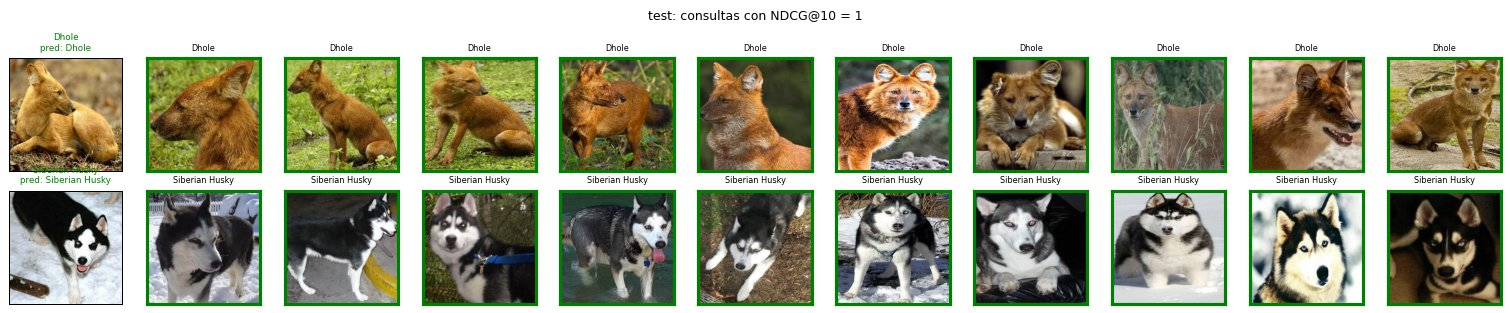

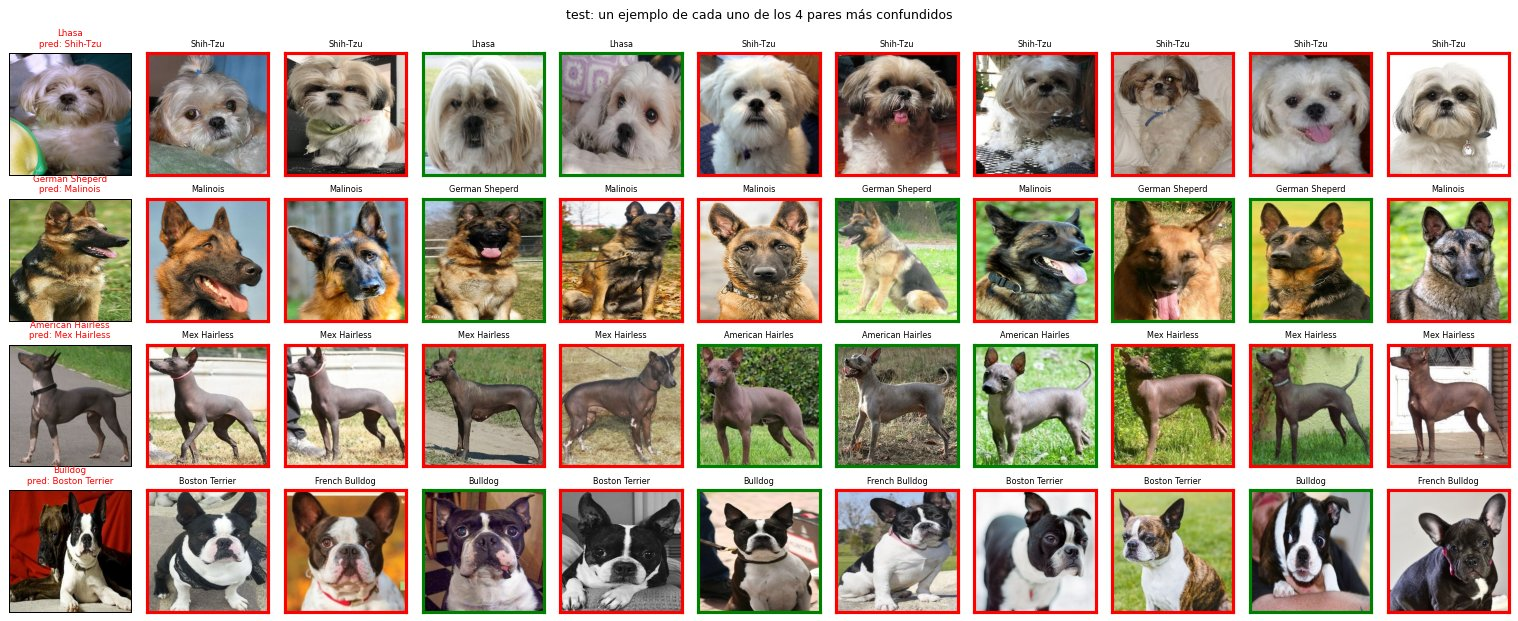

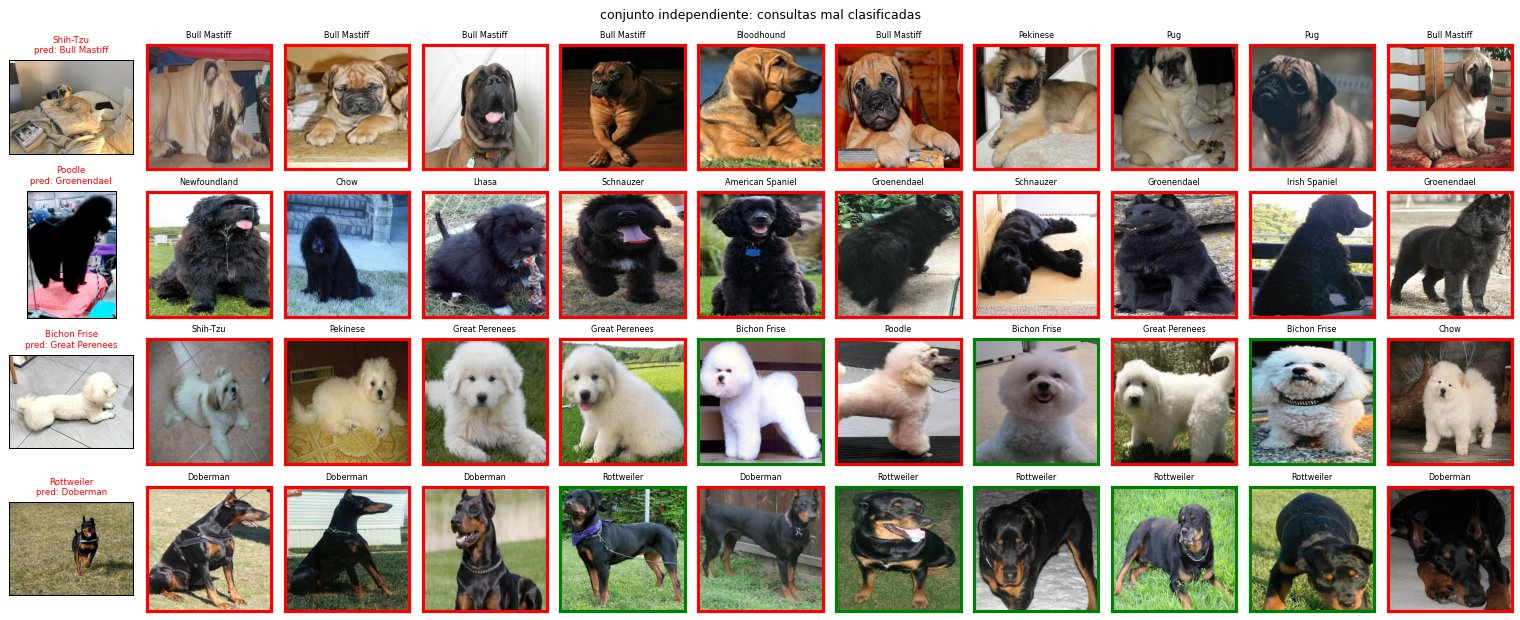

In [14]:
err = r_test[~r_test.ok]
pairs = (err.breed + "  →  " + err.pred).value_counts()
print(f"Errores en test: {len(err)} de {len(r_test)}")
display(pairs.head(12).rename("errores").to_frame())


def show_top10(rows, title):
    fig, axes = plt.subplots(len(rows), 11, figsize=(17, 1.75 * len(rows)))
    axes = np.atleast_2d(axes)
    for r, (_, row) in enumerate(rows.iterrows()):
        ax = axes[r, 0]
        ax.imshow(bgr_to_rgb(read_bgr(row.path)))
        ax.set_title(f"{row.breed}\npred: {row.pred}", fontsize=7, color="green" if row.ok else "red")
        for j, g in enumerate(row.top10):
            ax = axes[r, j + 1]
            ax.imshow(bgr_to_rgb(read_bgr(settings.dataset_path / G_PATH[g])))
            ok = G_BREED[g] == row.breed
            for s in ax.spines.values():
                s.set_edgecolor("green" if ok else "red")
                s.set_linewidth(2.5)
            ax.set_title(G_BREED[g][:16], fontsize=6.5)
    for ax in axes.ravel():
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()


rng = np.random.default_rng(SEED)
good = r_test[r_test["ndcg@10"] == 1].sample(2, random_state=SEED)
show_top10(good, "test: consultas con NDCG@10 = 1")
worst_pairs = pairs.head(4).index
bad = pd.concat([err[(err.breed + "  →  " + err.pred) == p].sample(1, random_state=SEED) for p in worst_pairs])
show_top10(bad, "test: un ejemplo de cada uno de los 4 pares más confundidos")
show_top10(r_ind[~r_ind.ok].sample(4, random_state=SEED), "conjunto independiente: consultas mal clasificadas")

**Interpretación de los errores.**

- **Una cuarta parte de los errores de `test` (34 de 143) está en 5 pares de razas**
  (Lhasa → Shih-Tzu, German Sheperd → Malinois, American Hairless → Mex Hairless,
  Bulldog → Boston Terrier y Cockapoo ↔ Labradoodle), y el resto de la lista sigue el mismo
  patrón de razas emparentadas (Cairn → Scotch Terrier, Collie → Border Collie). Son razas que se diferencian por detalles (largo del hocico, largo del
  pelo, el manto negro del pastor alemán) que el embedding de ImageNet no prioriza: en la fila del
  Lhasa, los Shih-Tzu recuperados tienen el mismo pelaje y la misma cara.
- **La clase Bulldog del dataset es ruidosa:** en la cuarta fila, las imágenes etiquetadas
  "Bulldog" que se recuperan (borde verde) tienen orejas de murciélago y la máscara blanca y negra
  del Boston Terrier o del French Bulldog. Con etiquetas mezcladas, ningún embedding puede separar
  bien la clase; explica que Bulldog sea la peor raza de `test`.
- **En el conjunto independiente los errores son de otro tipo:**
  - **perro chico dentro de una foto amplia** (Shih-Tzu sobre una cama, Rottweiler en un campo):
    el embedding describe la escena entera y no al perro;
  - **el color domina:** el Poodle negro recupera perros negros de cualquier raza (Newfoundland,
    Chow, Schnauzer) y el Bichon Frise acostado recupera perros blancos y peludos;
  - **pose:** los perros acostados recuperan otros perros acostados (Bull Mastiff).
- **Qué sugiere:** el baseline codifica color, textura, pose y fondo además de la raza. El
  fine-tuning (Modelo A, sección 6) debería llevar el embedding a los rasgos que separan razas; y
  recortar al perro con YOLO antes de buscar (como hace la Etapa 3) acercaría las fotos completas
  al dominio de la galería.

### 5.9 Configuración elegida para la Etapa 1

| Parámetro | Valor | Justificación |
|---|---|---|
| Extractor (`EMBEDDING_MODEL`) | `baseline`: ResNet18 de ImageNet, 512 | Misma dimensión y arquitectura que el Modelo A; se compara con los modelos entrenados en la sección 9 |
| `SIMILARITY_METRIC` | `cosine` | Igual ranking que `l2` con embeddings normalizados (5.4); es la métrica que pgvector usa para ordenar (`<=>`) |
| `TOP_K` | 10 | A menos de 0,2 puntos del máximo de accuracy en test y valid (5.6) |
| `SIMILARITY_THRESHOLD` | 0,77 | Percentil 0,1 del score top-1 de valid; rechaza el 75% de las fotos sin perro sin perder aciertos en el independiente y con 0,2 puntos menos en test (5.7) |

Resultado del baseline: **NDCG@10 = 0,817 en `test` y 0,595 en el conjunto independiente**
(accuracy 0,889 y 0,69).

## 6. Modelo A (obligatorio): fine-tuning de ResNet

`train_classifier` debe guardar el checkpoint en `models/resnet18_finetuned.pth`
(o el nombre configurado en `RESNET18_MODEL_NAME`). Documentar la estrategia de fine-tuning
y los hiperparámetros utilizados (learning rate, batch size, epochs, optimizador, scheduler,
regularización).

In [ ]:
from lib.bootstrap import build_classifier

classifier = build_classifier(settings)
classifier.set_active_model("resnet18_finetuned")
classifier.train_classifier()

In [ ]:
metrics_a = classifier.evaluate_classifier()
metrics_a

### Curvas de entrenamiento y matriz de confusión (Modelo A)

TO-DO: graficar las curvas de entrenamiento/validación (loss y accuracy) y la matriz de confusión
normalizada, con los pares de razas más confundidos.

In [ ]:
## TO-DO: curvas de entrenamiento y matriz de confusión del Modelo A.

## 7. Modelo B (obligatorio): CNN propia

`train_classifier` con el modelo activo `cnn_custom` debe guardar el checkpoint en
`models/cnn_custom.pth` (o el nombre configurado en `CNN_CUSTOM_MODEL_NAME`).
Definí la arquitectura en un módulo importable (por ejemplo, `src/lib/models/cnn_custom.py`):
si la clase vive en la notebook, `torch.load` falla en la app.

TO-DO: documentar la arquitectura (capas, parámetros, dimensión del embedding), los
hiperparámetros y la tabla de experimentos.

In [ ]:
classifier.set_active_model("cnn_custom")
classifier.train_classifier()

In [ ]:
metrics_b = classifier.evaluate_classifier()
metrics_b

### Curvas de entrenamiento y matriz de confusión (Modelo B)

In [ ]:
## TO-DO: curvas de entrenamiento y matriz de confusión del Modelo B.

## 8. Evaluación sobre el conjunto independiente

TO-DO: las mismas métricas sobre el conjunto independiente para ambos modelos. Comparar con `test`
y discutir el cambio de dominio.

In [ ]:
## TO-DO: métricas de ambos modelos sobre el conjunto independiente.

## 9. Embeddings de los modelos entrenados

TO-DO:
- NDCG@10 de la Etapa 1 con los embeddings del baseline, del Modelo A y del Modelo B
  (`classifier.extract_custom_embedding`), con la misma galería y las mismas consultas.
- Visualización PCA o t-SNE de los embeddings de `test` de cada modelo, lado a lado y coloreada
  por raza (con un subconjunto de razas).

In [ ]:
## TO-DO: NDCG@10 por modelo de embeddings y visualización PCA / t-SNE.

## 10. Análisis de errores

TO-DO: ejemplos de falsos positivos y falsos negativos con la imagen y su score, razas con peor
desempeño e hipótesis sobre las causas.

In [ ]:
## TO-DO: análisis de errores con ejemplos visuales.

## 11. Costo computacional

TO-DO: cantidad de parámetros, tamaño en MB, tiempo de inferencia por imagen en CPU y dimensión
del embedding de cada modelo.

In [ ]:
## TO-DO: costo computacional de cada modelo.

## 12. Comparación y elección final

TO-DO:
- Tabla comparativa de todas las métricas (Modelo A, Modelo B y baseline en la Etapa 1).
- Qué modelo usa la app para clasificar (Etapas 2 y 3) y qué embeddings para la búsqueda
  (`EMBEDDING_MODEL`), con su justificación.
- Búsqueda por similitud vs. clasificación supervisada: ventajas, limitaciones y cuándo conviene cada una.
- Trade-offs entre precisión, velocidad de inferencia, memoria y complejidad.

In [ ]:
## TO-DO: tabla comparativa final.

## 13. Descargar los checkpoints

Descargalos y colocalos en `models/` de tu entorno local para que la aplicación los use.
Recordá publicarlos en un link público de solo lectura y ponerlo en el README y en el PR.

In [ ]:
!ls -lh models/

try:
    from google.colab import files

    files.download(str(settings.model_path / settings.resnet18_model_name))
    files.download(str(settings.model_path / settings.cnn_custom_model_name))
except ImportError:
    print("Fuera de Colab: los checkpoints quedan en models/")